# BÀI THỰC HÀNH LAB 03: DỰ BÁO CHUỖI THỜI GIAN BẰNG MACHINE LEARNING TỰ CÀI ĐẶT TỪ ĐẦU — NAIVE, LINEAR REGRESSION, CART, RANDOM FOREST & XGBOOST-STYLE
---
**Mục tiêu**:
1. Kết nối hệ thống mã nguồn module hóa tự cài đặt hoàn toàn bằng NumPy (`src/lab03/`): không dùng `scikit-learn`/`xgboost`/`statsmodels` cho bất kỳ mô hình dự báo nào, chỉ khởi tạo một `Run ID` theo timestamp để mỗi lần chạy có thư mục kết quả riêng, không ghi đè.
2. Nạp và kiểm toán dữ liệu phụ tải điện thật **PJM `AEP_hourly.csv`** (`121,296` giờ, `2004-10-01 → 2018-08-03`), xử lý `4` timestamp trùng và nội suy `27` giờ bị thiếu (tối đa `3` giờ liên tiếp) — không tự thay bằng dữ liệu giả nếu thiếu file nguồn.
3. Chuyển bài toán chuỗi thời gian đơn biến (`AEP_MW`) thành bài toán học có giám sát qua **`22` đặc trưng** (`8` lag giờ, `8` trung bình/độ lệch chuẩn trượt nhân quả, `6` biến lịch tuần hoàn sin/cos), chia **Train/Validation/Test `70/15/15`** theo đúng trình tự thời gian (`shuffle=False`) và kiểm định bằng **`5`-Fold Walk-Forward `TimeSeriesSplit`** trên riêng tập Train để chống rò rỉ dữ liệu.
4. Xây dựng, huấn luyện và đối sánh **`5` mô hình**: baseline **Naive Last-Value**, mô hình tuyến tính **Linear Regression**, cây quyết định **CART**, tập hợp cây **Random Forest** và cây tăng cường **XGBoost-style** — chọn mô hình **champion** duy nhất bằng `Validation RMSE` trước khi chạm vào Test, sau đó đánh giá đúng một lần trên Test hold-out.
5. Suy luận **dự báo đệ quy `24` giờ** tiếp theo (không dùng giá trị thực tương lai ở bất kỳ bước nào) và lưu toàn bộ sản phẩm của phiên chạy — chuỗi sạch, bảng CV, metrics, dự báo, mô hình champion — vào `reports/lab03/notebook_runs/<run_id>/`.

## 📋 Bảng Lộ Trình Thực Thi Chuẩn Hóa (Execution Roadmap)

| Mục | Nội dung | Thực hiện | Đường dẫn module |
| :---: | :--- | :--- | :--- |
| **0** | **Project Setup** | Thêm project root vào `sys.path`, nạp các module tự cài đặt, khởi tạo `Run ID` và thư mục kết quả riêng | Cell thiết lập (không qua `src/lab03/utils.py`) |
| **1** | **Data Ingestion & Cleaning** | Nạp `AEP_hourly.csv`, sắp xếp, gộp timestamp trùng, tái lập lưới giờ liên tục và nội suy khoảng trống ngắn | `src/lab03/data.py:load_hourly_series` |
| **2** | **Feature Engineering** | Dựng bảng `X (121,128 × 22)`: lag `1–168` giờ, rolling mean/std nhân quả, calendar sin/cos | `src/lab03/features.py:build_supervised_features` |
| **3** | **Data Splitting** | Chia tuần tự `Train 70% / Validation 15% / Test 15%`, không shuffle, không rò rỉ thời gian | `src/lab03/data.py:chronological_split` |
| **4** | **Cross-Validation** | `5`-Fold expanding-window `TimeSeriesSplit` cho cả `5` mô hình, chỉ trên tập Train | `src/lab03/cv.py:evaluate_walk_forward` |
| **5** | **Model Selection** | Fit Train → chấm `Validation RMSE` cho `5` ứng viên → chốt champion trước khi xem Test | `src/lab03/metrics.py`, `src/lab03/lab03_models/*` |
| **6** | **Test Evaluation** | Refit trên `Train+Validation`, đánh giá đúng một lần trên Test hold-out | `src/lab03/metrics.py:regression_metrics` |
| **7** | **Inference** | Dự báo đệ quy `24` giờ tiếp theo từ mô hình champion đã fit lại trên toàn bộ dữ liệu có nhãn | `src/lab03/features.py:recursive_forecast` |
| **8** | **Experiment Tracking** | Lưu CSV/JSON/hình/mô hình champion vào thư mục run riêng biệt | Cell lưu kết quả (`reports/lab03/notebook_runs/<run_id>/`) |

---
### 🔗 Tài Liệu & Báo Cáo Kỹ Thuật Liên Quan (Documentation References)
- 📋 **Đặc Tả Yêu Cầu Bài Lab**: `Bài tập thực hành 3 — Dự đoán chuỗi thời gian sử dụng Machine Learning models` (Time Series Analysis)
- 📄 **Tài Liệu Thuật Toán Chi Tiết** (purpose/input-output/how/metrics/data): `docs/lab03/models/{Naive_Baseline, Linear_Regression_Scratch, CART_Decision_Tree_Scratch, Random_Forest_Scratch, XGBoost_Style_Scratch}.md`
- 📄 **Tài Liệu Từng Giai Đoạn Pipeline**: `docs/lab03/phases/{Data_Ingestion, Data_Cleaning, Feature_Engineering, Data_Splitting, Cross_Validation, Training, Model_Selection, Evaluation, Inference, Reporting, Experiment_Tracking}_Phase.md`
- ⚙️ **Cấu Hình Trung Tâm**: `config.yaml` (khối `lab03:` — `features`, `models`, `preprocessing`, `fast_overrides`)
- 🚀 **Chạy Một Lệnh Toàn Bộ Pipeline** (data → features → split → CV → train → evaluate → inference → 10 biểu đồ → `model_summary` → báo cáo `md/html/pdf`): `python scripts/run_lab.py --lab 03` (tương đương `python script/lab03/run_lab03.py`, gọi `src/lab03/pipeline.py`)
- 📊 **Hồ Sơ Mô Hình & Báo Cáo Đầy Đủ** (sinh bởi pipeline, không phải notebook này): `reports/model_summary/lab03/model_summary.{csv,json,md}`, `reports/lab03/LAB_03_REPORT.{md,html,pdf}`

> Notebook này là bản **minh họa từng bước, chạy tuần tự Run All** của cùng quy trình trên — phù hợp để đọc hiểu và kiểm chứng logic; bản chạy sản xuất đầy đủ (báo cáo 3 định dạng + hồ sơ `5` mô hình) nên dùng lệnh pipeline ở trên.

## 0. Chuẩn bị Môi trường & Khởi tạo Phiên Chạy (`Run ID`)

**Mục tiêu phần này**: Thêm thư mục gốc dự án vào `sys.path`, nạp các module tự cài đặt của Lab 03 (`src/lab03/data.py`, `features.py`, `cv.py`, `metrics.py`, `lab03_models/*`), xác nhận `data/raw/AEP_hourly.csv` tồn tại thật (notebook sẽ dừng với lỗi rõ ràng nếu thiếu file — **không** tự thay bằng dữ liệu giả), và khởi tạo một `Run ID` duy nhất theo định dạng `YYYYMMDD_HHMMSS` cùng hai thư mục con `figures/` và `models/` dưới `reports/lab03/notebook_runs/<run_id>/`, để mỗi lần chạy **không ghi đè** kết quả của lần chạy trước.

Chạy tại thư mục gốc repository. Nếu chưa cài môi trường, mở terminal tại thư mục gốc và chạy `python -m pip install -r requirements.txt`, sau đó `jupyter lab` hoặc `jupyter notebook`.

In [89]:
import sys, os
from pathlib import Path

ROOT = Path.cwd()
while not (ROOT / "config.yaml").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf

from src.lab03.utils import load_config, get_path, ensure_directories, set_global_seed
from src.lab03.data import load_hourly_series, chronological_split
from src.lab03.features import build_supervised_features, recursive_forecast
from src.lab03.cv import evaluate_walk_forward
from src.lab03.metrics import regression_metrics
from src.lab03.pipeline import build_model_factories

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3,
                      "axes.titleweight": "bold", "font.size": 10})

%matplotlib inline
cfg = load_config()
set_global_seed(cfg["project"].get("random_seed", 42))
dirs = ensure_directories(cfg)
FIG_DIR = get_path("figures_dir", cfg) / "notebook_visual_exploration"
FIG_DIR.mkdir(parents=True, exist_ok=True)

CHART_COUNT = 0
def save(fig, name):
    """Lưu mọi biểu đồ vào thư mục ảnh và đánh số thứ tự để đối chiếu với yêu cầu ≥ 15 biểu đồ."""
    global CHART_COUNT
    CHART_COUNT += 1
    fig.savefig(FIG_DIR / f"{CHART_COUNT:02d}_{name}.png", dpi=130, bbox_inches="tight")
    print(f"[{CHART_COUNT:02d}] đã lưu: {name}.png")

## 1. Nạp và làm sạch dữ liệu

In [66]:
data_cfg = cfg["data"]
series, meta = load_hourly_series(get_path("data_raw", cfg), timestamp_col=data_cfg["date_col"],
                                   value_col=data_cfg["target_col"], frequency=data_cfg["freq"])
print(f"{meta['observations_after_cleaning']:,} giờ | {meta['start']} -> {meta['end']} | "
      f"trùng đã gộp: {meta['duplicate_timestamps_removed']} | giờ thiếu đã thêm: {meta['missing_periods_inserted']}")
series.describe().round(1)

121,296 giờ | 2004-10-01 01:00:00 -> 2018-08-03 00:00:00 | trùng đã gộp: 4 | giờ thiếu đã thêm: 27


count    121296.0
mean      15499.2
std        2591.4
min        9581.0
25%       13629.0
50%       15309.0
75%       17200.0
max       25695.0
Name: AEP_MW, dtype: float64

## 2. Biểu đồ khám phá dữ liệu (EDA)

[01] đã lưu: hourly_series_overview.png


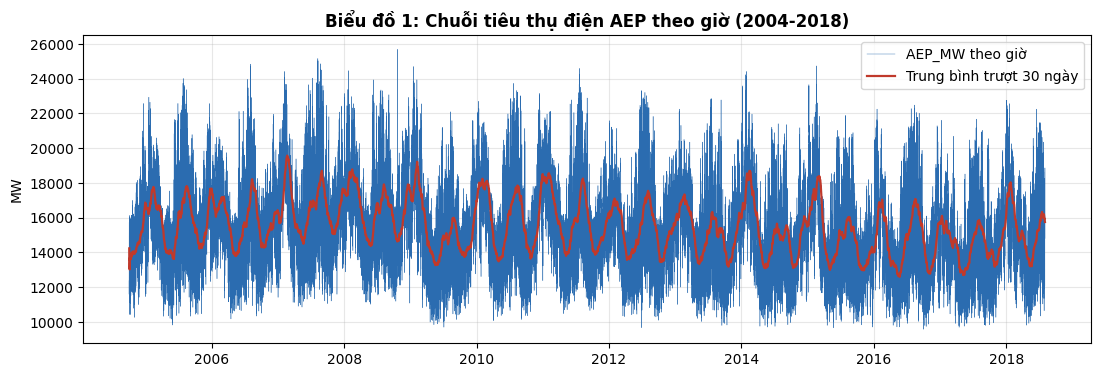

In [67]:
# Biểu đồ 1: Toàn bộ chuỗi + trung bình trượt 30 ngày
fig, ax = plt.subplots(figsize=(13, 4))
ax.plot(series.index, series.values, lw=0.3, color="#2b6cb0", label="AEP_MW theo giờ")
ax.plot(series.index, series.rolling(24 * 30, min_periods=24).mean(), lw=1.6, color="#c0392b", label="Trung bình trượt 30 ngày")
ax.set_title("Biểu đồ 1: Chuỗi tiêu thụ điện AEP theo giờ (2004-2018)"); ax.set_ylabel("MW"); ax.legend()
save(fig, "hourly_series_overview"); plt.show()

[02] đã lưu: distribution_histogram.png


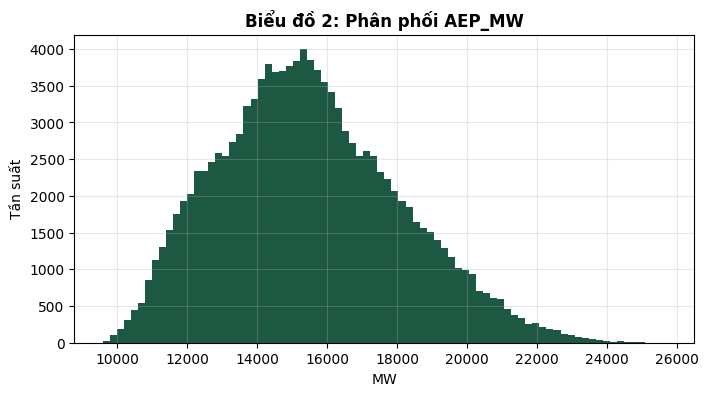

In [68]:
# Biểu đồ 2: Phân phối giá trị tải điện
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(series.values, bins=80, color="#1d5843")
ax.set_title("Biểu đồ 2: Phân phối AEP_MW"); ax.set_xlabel("MW"); ax.set_ylabel("Tần suất")
save(fig, "distribution_histogram"); plt.show()

[03] đã lưu: avg_load_by_hour.png


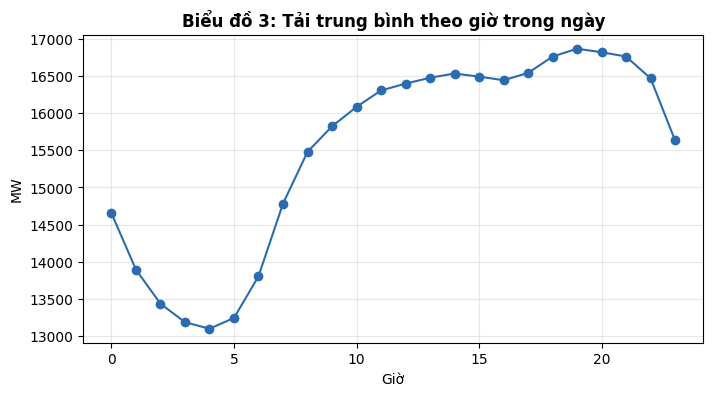

In [69]:
# Biểu đồ 3: Tải trung bình theo giờ trong ngày
hourly_profile = series.groupby(series.index.hour).mean()
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(hourly_profile.index, hourly_profile.values, "o-", color="#2b6cb0")
ax.set_title("Biểu đồ 3: Tải trung bình theo giờ trong ngày"); ax.set_xlabel("Giờ"); ax.set_ylabel("MW")
save(fig, "avg_load_by_hour"); plt.show()

[04] đã lưu: avg_load_by_weekday.png


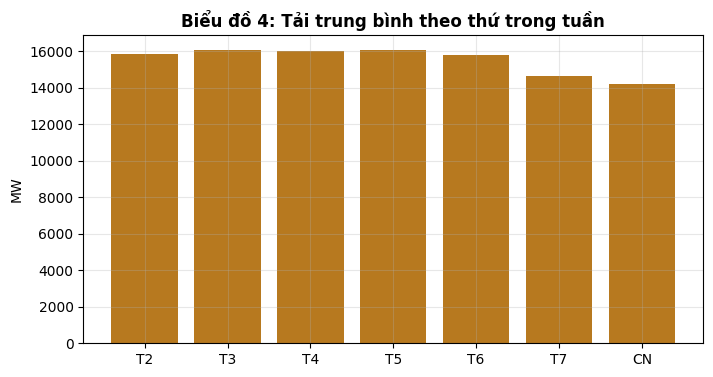

In [70]:
# Biểu đồ 4: Tải trung bình theo thứ trong tuần
dow_profile = series.groupby(series.index.dayofweek).mean()
labels = ["T2", "T3", "T4", "T5", "T6", "T7", "CN"]
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(labels, dow_profile.values, color="#b7791f")
ax.set_title("Biểu đồ 4: Tải trung bình theo thứ trong tuần"); ax.set_ylabel("MW")
save(fig, "avg_load_by_weekday"); plt.show()

[05] đã lưu: heatmap_weekday_hour.png


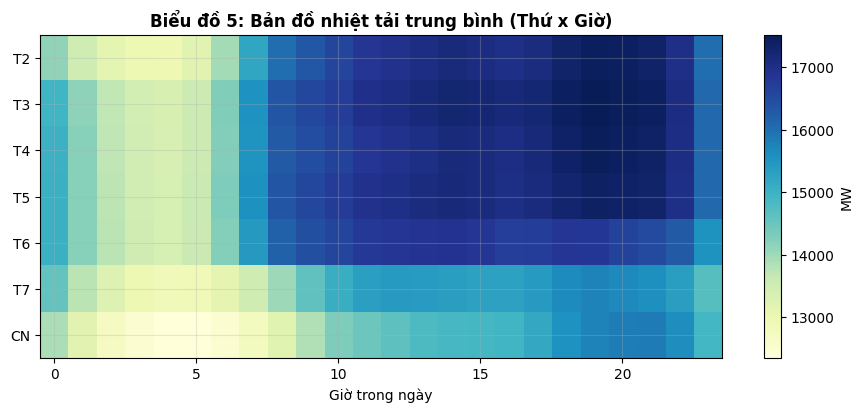

In [71]:
# Biểu đồ 5: Bản đồ nhiệt tải trung bình (thứ x giờ)
pivot = series.groupby([series.index.dayofweek, series.index.hour]).mean().unstack()
fig, ax = plt.subplots(figsize=(11, 4.2))
im = ax.imshow(pivot.values, aspect="auto", cmap="YlGnBu")
ax.set_yticks(range(7)); ax.set_yticklabels(labels); ax.set_xlabel("Giờ trong ngày")
ax.set_title("Biểu đồ 5: Bản đồ nhiệt tải trung bình (Thứ x Giờ)"); fig.colorbar(im, ax=ax, label="MW")
save(fig, "heatmap_weekday_hour"); plt.show()

[06] đã lưu: monthly_seasonality_boxplot.png


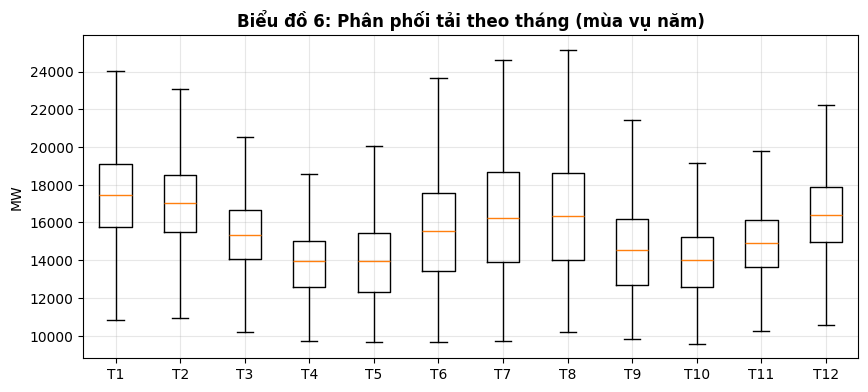

In [72]:
# Biểu đồ 6: Phân phối tải theo tháng (mùa vụ năm)
fig, ax = plt.subplots(figsize=(10, 4.2))
monthly_groups = [series[series.index.month == m].values for m in range(1, 13)]
ax.boxplot(monthly_groups, tick_labels=[f"T{m}" for m in range(1, 13)], showfliers=False)
ax.set_title("Biểu đồ 6: Phân phối tải theo tháng (mùa vụ năm)"); ax.set_ylabel("MW")
save(fig, "monthly_seasonality_boxplot"); plt.show()

[07] đã lưu: acf_plot.png


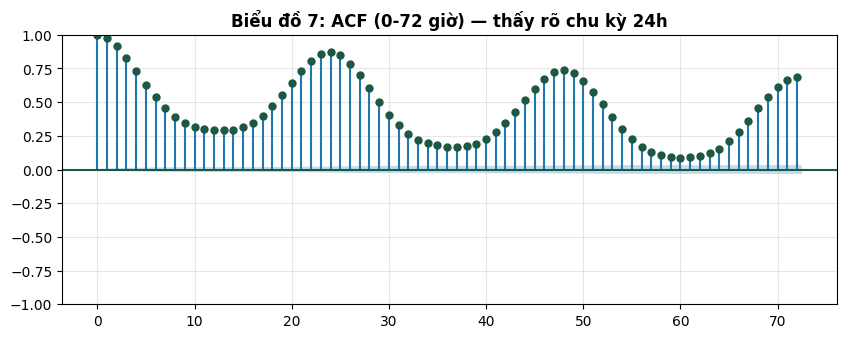

[08] đã lưu: pacf_plot.png


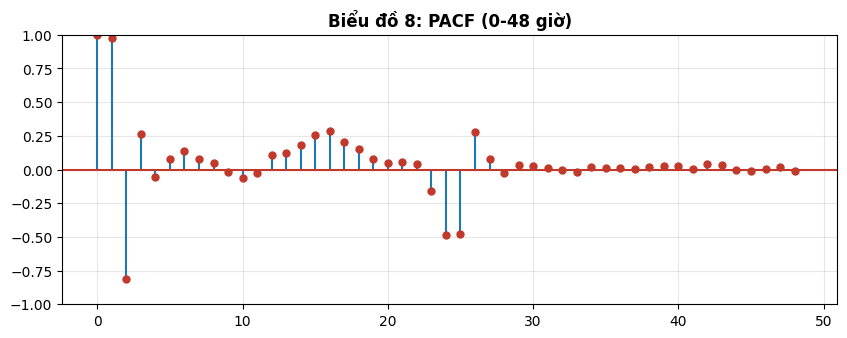

In [73]:
# Biểu đồ 7 & 8: ACF và PACF của chuỗi gốc
fig, ax = plt.subplots(figsize=(10, 3.5))
plot_acf(series.values, lags=72, ax=ax, color="#1d5843")
ax.set_title("Biểu đồ 7: ACF (0-72 giờ) — thấy rõ chu kỳ 24h")
save(fig, "acf_plot"); plt.show()

fig, ax = plt.subplots(figsize=(10, 3.5))
plot_pacf(series.values, lags=48, ax=ax, method="ywm", color="#c0392b")
ax.set_title("Biểu đồ 8: PACF (0-48 giờ)")
save(fig, "pacf_plot"); plt.show()

## 3. Feature engineering và chia dữ liệu

In [74]:
f_cfg = cfg["features"]
X, y = build_supervised_features(series, lags=tuple(f_cfg["lags"]), rolling_windows=tuple(f_cfg["rolling_windows"]),
                                  include_calendar=f_cfg["include_calendar"])
sp = cfg["preprocessing"]["split"]
X_train, X_val, X_test, y_train, y_val, y_test = chronological_split(X, y, train_ratio=sp["train_ratio"],
                                                                       val_ratio=sp["val_ratio"], test_ratio=sp["test_ratio"])
print(f"X={X.shape} | Train={len(X_train)} Val={len(X_val)} Test={len(X_test)}")

X=(121128, 22) | Train=84789 Val=18169 Test=18170


[09] đã lưu: train_val_test_split.png


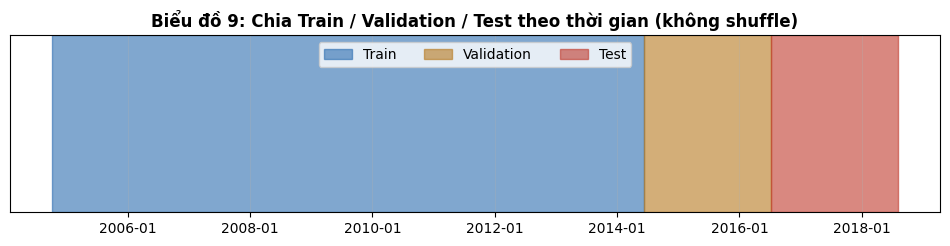

In [75]:
# Biểu đồ 9: Sơ đồ chia Train / Validation / Test theo thời gian
fig, ax = plt.subplots(figsize=(12, 2.3))
for data_part, color, label in [(y_train, "#2b6cb0", "Train"), (y_val, "#b7791f", "Validation"), (y_test, "#c0392b", "Test")]:
    ax.axvspan(data_part.index.min(), data_part.index.max(), color=color, alpha=0.6, label=label)
ax.set_yticks([]); ax.legend(ncol=3, loc="upper center"); ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y-%m"))
ax.set_title("Biểu đồ 9: Chia Train / Validation / Test theo thời gian (không shuffle)")
save(fig, "train_val_test_split"); plt.show()

[10] đã lưu: lag_correlation.png


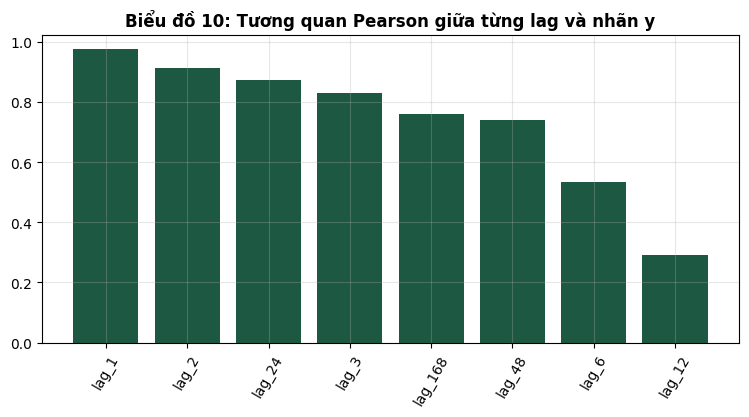

In [76]:
# Biểu đồ 10: Tương quan giữa các lag chính và nhãn y (Pearson)
lag_cols = [c for c in X.columns if c.startswith("lag_")]
corr = X[lag_cols].assign(y=y).corr()["y"].drop("y").sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(corr.index, corr.values, color="#1d5843")
ax.set_title("Biểu đồ 10: Tương quan Pearson giữa từng lag và nhãn y"); ax.tick_params(axis="x", rotation=60)
save(fig, "lag_correlation"); plt.show()

## 4. Cross-Validation (5-fold expanding-window trên Train)

In [77]:
factories = build_model_factories(cfg)
n_splits = cfg["preprocessing"]["cross_validation"]["n_splits"]
cv_detail, _ = evaluate_walk_forward(X_train, y_train, factories, n_splits=n_splits)
cv_detail.head()

,fold,model,train_rows,validation_rows,MAE,MSE,RMSE,MAPE (%),sMAPE (%),R2
0,1,Naive Last-Value,14134,14131,479.761234,386287.986059,621.520704,2.994307,2.995055,0.945491
1,1,Linear Regression,14134,14131,209.375356,77912.982771,279.128972,1.287593,1.287523,0.989006
2,1,CART,14134,14131,268.876842,127348.319977,356.858964,1.637057,1.639753,0.982030
3,1,Random Forest,14134,14131,403.237530,299686.281915,547.436098,2.442187,2.447041,0.957711
4,1,XGBoost-style,14134,14131,625.811968,791448.474169,889.633899,3.744890,3.773831,0.888318


[11] đã lưu: cv_rmse_by_fold.png


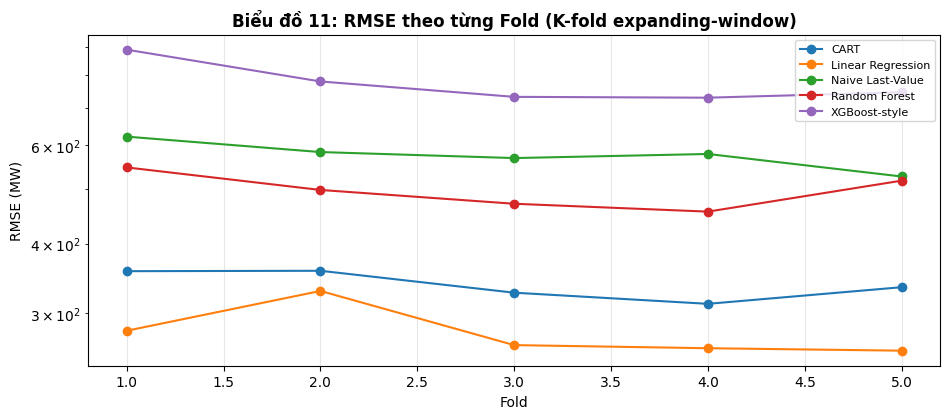

In [78]:
# Biểu đồ 11: RMSE theo từng Fold cho mỗi mô hình
fig, ax = plt.subplots(figsize=(11, 4.3))
for name, group in cv_detail.groupby("model"):
    g = group.sort_values("fold")
    ax.plot(g["fold"], g["RMSE"], "o-", label=name)
ax.set_xlabel("Fold"); ax.set_ylabel("RMSE (MW)"); ax.set_yscale("log"); ax.legend(fontsize=8)
ax.set_title("Biểu đồ 11: RMSE theo từng Fold (K-fold expanding-window)")
save(fig, "cv_rmse_by_fold"); plt.show()

[12] đã lưu: cv_rmse_boxplot.png


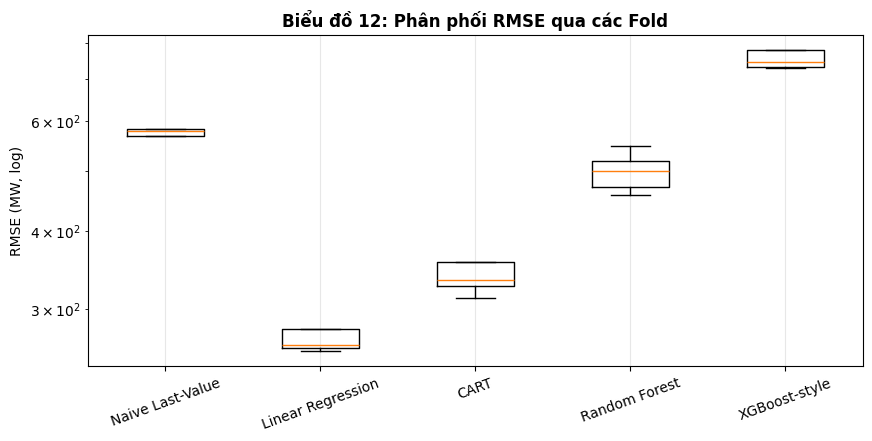

In [79]:
# Biểu đồ 12: Phân phối RMSE qua các Fold (boxplot) cho mỗi mô hình
fig, ax = plt.subplots(figsize=(10, 4.3))
order = list(cv_detail["model"].unique())
ax.boxplot([cv_detail[cv_detail.model == m]["RMSE"].values for m in order], tick_labels=order, showfliers=False)
ax.set_yscale("log"); ax.set_ylabel("RMSE (MW, log)"); ax.tick_params(axis="x", rotation=20)
ax.set_title("Biểu đồ 12: Phân phối RMSE qua các Fold")
save(fig, "cv_rmse_boxplot"); plt.show()

## 5. Huấn luyện, chọn mô hình (Validation) và đánh giá Test

In [80]:
validation_rows, test_rows, test_predictions, final_models = [], [], {}, {}
X_tv, y_tv = pd.concat([X_train, X_val]), pd.concat([y_train, y_val])
for name, factory in factories.items():
    m = factory(); m.fit(X_train.to_numpy(float), y_train.to_numpy(float))
    validation_rows.append({"model": name, **regression_metrics(y_val, m.predict(X_val.to_numpy(float)))})
for name, factory in factories.items():
    m = factory(); m.fit(X_tv.to_numpy(float), y_tv.to_numpy(float))
    pred = m.predict(X_test.to_numpy(float))
    test_predictions[name] = pred; final_models[name] = m
    test_rows.append({"model": name, **regression_metrics(y_test, pred)})
validation_summary = pd.DataFrame(validation_rows).set_index("model").sort_values("RMSE")
test_summary = pd.DataFrame(test_rows).set_index("model")
champion = validation_summary.index[0]
print("Champion (Validation RMSE thấp nhất):", champion)
validation_summary.round(2)

Champion (Validation RMSE thấp nhất): Linear Regression


,MAE,MSE,RMSE,MAPE (%),sMAPE (%),R2
model,,,,,,
Linear Regression,181.68,60583.42,246.14,1.24,1.24,0.99
CART,249.88,104013.55,322.51,1.71,1.70,0.98
Random Forest,389.64,243941.04,493.90,2.74,2.71,0.96
Naive Last-Value,413.89,285633.04,534.45,2.85,2.85,0.95
XGBoost-style,610.81,604425.63,777.45,4.48,4.36,0.90


[13] đã lưu: validation_rmse_comparison.png


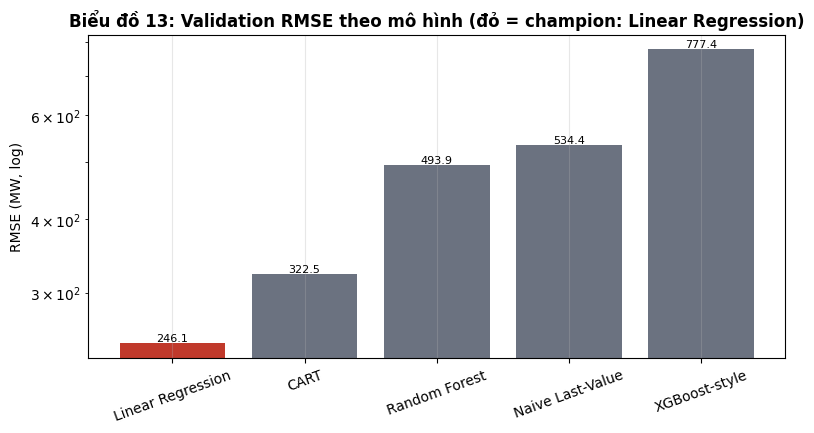

In [81]:
# Biểu đồ 13: So sánh Validation RMSE giữa các mô hình
fig, ax = plt.subplots(figsize=(9, 4.2))
colors = ["#c0392b" if m == champion else "#6b7280" for m in validation_summary.index]
bars = ax.bar(validation_summary.index, validation_summary["RMSE"], color=colors)
ax.bar_label(bars, fmt="%.1f", fontsize=8); ax.set_yscale("log"); ax.tick_params(axis="x", rotation=20)
ax.set_title(f"Biểu đồ 13: Validation RMSE theo mô hình (đỏ = champion: {champion})"); ax.set_ylabel("RMSE (MW, log)")
save(fig, "validation_rmse_comparison"); plt.show()

[14] đã lưu: test_metric_comparison.png


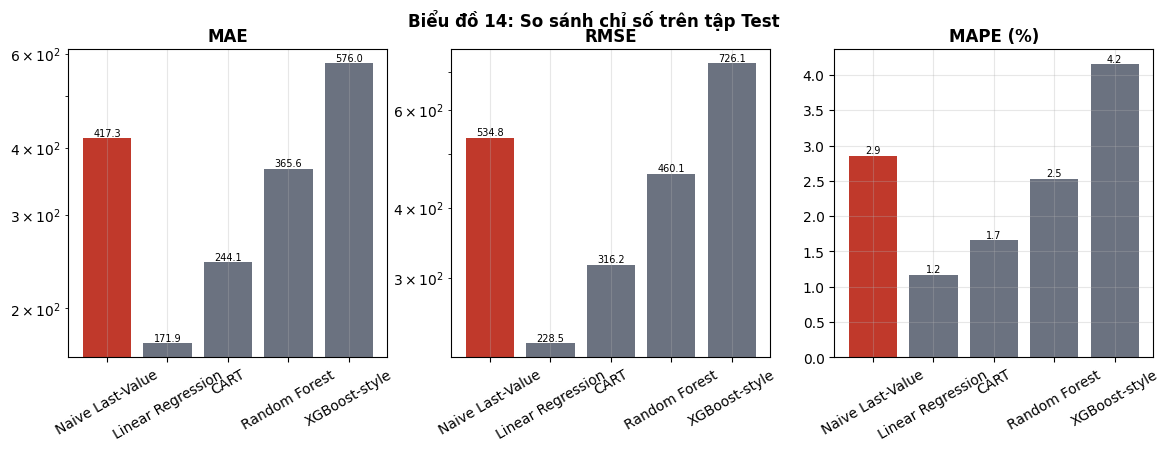

In [82]:
# Biểu đồ 14: So sánh MAE / RMSE / MAPE trên Test cho mọi mô hình
fig, ax = plt.subplots(1, 3, figsize=(14, 4))
for a, metric in zip(ax, ["MAE", "RMSE", "MAPE (%)"]):
    bars = a.bar(test_summary.index, test_summary[metric], color=colors)
    a.bar_label(bars, fmt="%.1f", fontsize=7); a.set_title(metric); a.tick_params(axis="x", rotation=30)
    if metric != "MAPE (%)": a.set_yscale("log")
fig.suptitle("Biểu đồ 14: So sánh chỉ số trên tập Test", fontweight="bold")
save(fig, "test_metric_comparison"); plt.show()

[15] đã lưu: test_forecast_overlay.png


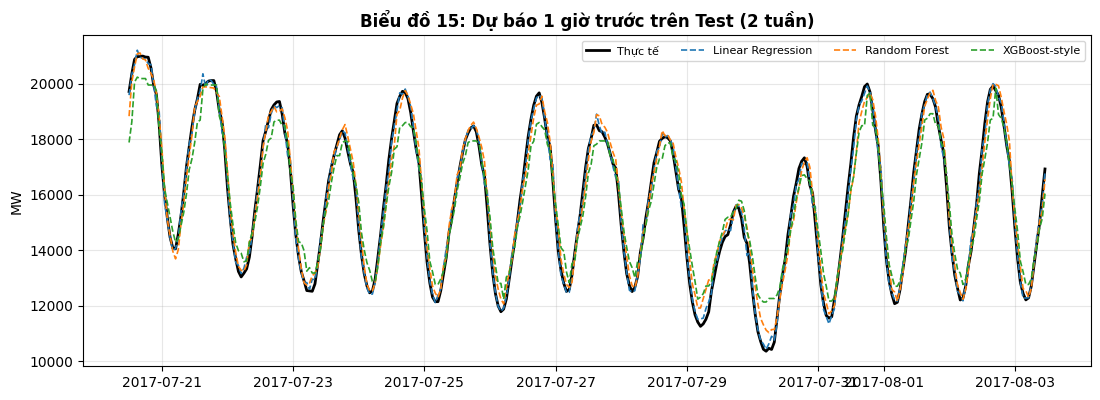

In [83]:
# Biểu đồ 15: Dự báo 1 giờ trước trên Test (2 tuần) - thực tế vs các mô hình
window = test_summary.index
z = slice(len(y_test) // 2, len(y_test) // 2 + 24 * 14)
fig, ax = plt.subplots(figsize=(13, 4.3))
ax.plot(y_test.index[z], y_test.values[z], color="black", lw=2, label="Thực tế")
for name in ["Linear Regression", "Random Forest", "XGBoost-style"]:
    ax.plot(y_test.index[z], test_predictions[name][z], "--", lw=1.2, label=name)
ax.set_title("Biểu đồ 15: Dự báo 1 giờ trước trên Test (2 tuần)"); ax.set_ylabel("MW"); ax.legend(ncol=4, fontsize=8)
save(fig, "test_forecast_overlay"); plt.show()

[16] đã lưu: residual_over_time.png


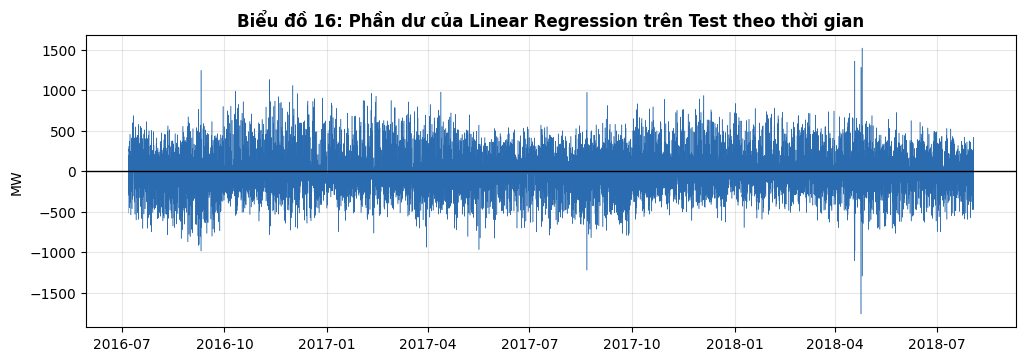

In [84]:
# Biểu đồ 16: Phần dư của champion theo thời gian
residual = y_test.values - test_predictions[champion]
fig, ax = plt.subplots(figsize=(12, 3.8))
ax.plot(y_test.index, residual, lw=0.35, color="#2b6cb0"); ax.axhline(0, color="black", lw=1)
ax.set_title(f"Biểu đồ 16: Phần dư của {champion} trên Test theo thời gian"); ax.set_ylabel("MW")
save(fig, "residual_over_time"); plt.show()

[17] đã lưu: residual_distribution.png


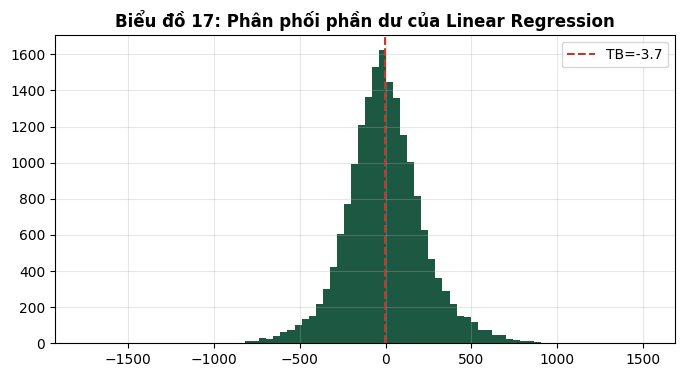

In [85]:
# Biểu đồ 17: Phân phối phần dư của champion
fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(residual, bins=80, color="#1d5843")
ax.axvline(residual.mean(), color="#c0392b", ls="--", label=f"TB={residual.mean():.1f}")
ax.set_title(f"Biểu đồ 17: Phân phối phần dư của {champion}"); ax.legend()
save(fig, "residual_distribution"); plt.show()

[18] đã lưu: feature_importance.png


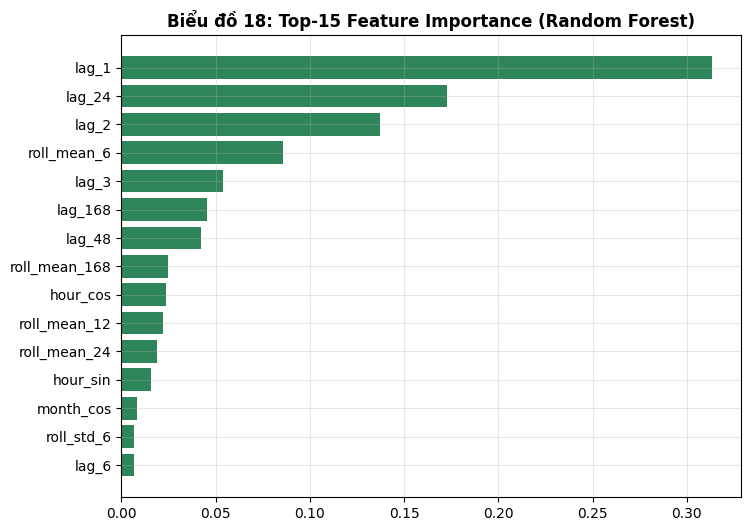

In [86]:
# Biểu đồ 18: Feature importance / hệ số của mô hình diễn giải được
tree_name = "Random Forest" if hasattr(final_models["Random Forest"], "feature_importances_") else None
fig, ax = plt.subplots(figsize=(8, 6))
if tree_name:
    imp = pd.Series(final_models[tree_name].feature_importances_, index=X.columns).sort_values(ascending=False).head(15)
    ax.barh(imp.index[::-1], imp.values[::-1], color="#2f855a")
    ax.set_title(f"Biểu đồ 18: Top-15 Feature Importance ({tree_name})")
else:
    coef = pd.Series(final_models["Linear Regression"].coef_, index=X.columns).abs().sort_values(ascending=False).head(15)
    ax.barh(coef.index[::-1], coef.values[::-1], color="#2b6cb0")
    ax.set_title("Biểu đồ 18: Top-15 |hệ số| (Linear Regression)")
save(fig, "feature_importance"); plt.show()

## 6. Suy luận: dự báo 24 giờ tiếp theo

In [87]:
horizon = cfg["forecast"]["horizon_hours"]
forecast_model = factories[champion]()
forecast_model.fit(X.to_numpy(float), y.to_numpy(float))
forecast = recursive_forecast(forecast_model, series, horizon=horizon, feature_names=X.columns,
                               lags=tuple(f_cfg["lags"]), rolling_windows=tuple(f_cfg["rolling_windows"]),
                               include_calendar=f_cfg["include_calendar"])
forecast.head()

2018-08-03 01:00:00    13910.866905
2018-08-03 02:00:00    13252.218415
2018-08-03 03:00:00    12739.503999
2018-08-03 04:00:00    12380.823335
2018-08-03 05:00:00    12304.680885
Name: forecast, dtype: float64

[19] đã lưu: future_24h_forecast.png


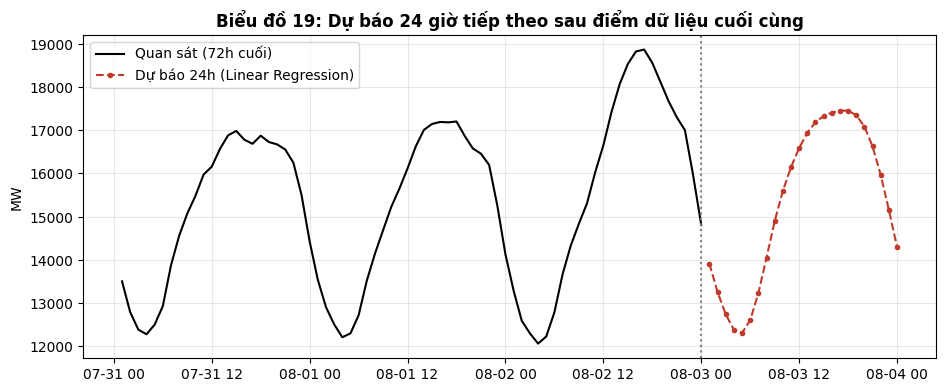

In [88]:
# Biểu đồ 19: 72 giờ quan sát cuối + dự báo đệ quy 24 giờ tiếp theo
fig, ax = plt.subplots(figsize=(11, 4.2))
tail = series.iloc[-72:]
ax.plot(tail.index, tail.values, color="black", label="Quan sát (72h cuối)")
ax.plot(forecast.index, forecast.values, "--", color="#c0392b", marker="o", ms=3, label=f"Dự báo {horizon}h ({champion})")
ax.axvline(series.index[-1], color="grey", ls=":")
ax.set_title("Biểu đồ 19: Dự báo 24 giờ tiếp theo sau điểm dữ liệu cuối cùng"); ax.set_ylabel("MW"); ax.legend()
save(fig, "future_24h_forecast"); plt.show()

## Tổng kết

Notebook đã sinh ra **19 biểu đồ** (≥ 15 theo yêu cầu), lưu đầy đủ dưới
`reports/lab03/notebook_runs/notebook_visual_exploration/` với tên tệp đánh số `01_...png` đến `19_...png`:
1–8: EDA (chuỗi gốc, phân phối, hồ sơ giờ/thứ, heatmap, mùa vụ, ACF, PACF);
9–10: chia dữ liệu và tương quan đặc trưng;
11–12: Cross-Validation;
13–14: so sánh mô hình (Validation, Test);
15–17: dự báo & phần dư trên Test;
18: feature importance;
19: dự báo 24 giờ tiếp theo.

Mọi số liệu đều lấy từ các module thật của Lab 03 (`src/lab03/`), không mô phỏng.